# Parte II - Algoritmos (implementação própria + complexidade teórica x observada)

**Pré-requisito:** executar o notebook 01 (gera data/processed/*.edgelist).

**Decisões de projeto**

1. **Implementação própria dos 8 algoritmos** (BFS, DFS, Eulerianidade, Dijkstra, Bellman-Ford, Floyd-Warshall, Tarjan,
   AGM Prim/Kruskal), só com estruturas da biblioteca padrão (deque, heapq) e NumPy (vetorização do laço interno do Floyd-Warshall).
   O NetworkX é usado **somente para verificar a corretude** das implementações.
2. **Pesos:** o Gnutella06 não tem pesos. Para Dijkstra, Bellman-Ford, Floyd-Warshall e AGM serem testes significativos
   (com peso 1, Dijkstra vira BFS e toda AGM pesa |V|−1), atribuímos **pesos inteiros aleatórios em [1, 100]** às arestas
   (semente fixa). Os pesos são não negativos, logo Dijkstra é aplicável. Bellman-Ford também (serve de verificação cruzada).
3. **Grafo usado:** BFS, DFS, Dijkstra, Bellman-Ford, Floyd-Warshall e AGM rodam no **grafo não direcionado** (é conexo, AGM só
   existe para grafo não direcionado). Tarjan roda no **direcionado** (SCC só faz sentido em dirigido). Eulerianidade nos dois.
4. **Floyd-Warshall** é O(|V|³) em tempo e O(|V|²) em memória: com |V| = 8 717 seriam ~6,6·10¹¹ operações e ~600 MB.
   Por isso é medido em **subgrafos induzidos conexos de 100 a 500 vértices** (BFS a partir do maior hub).
5. **Complexidade observada:** não basta um único tamanho. Cada algoritmo é medido em subgrafos de tamanhos crescentes e
   ajustamos a **inclinação em log-log do tempo x modelo de custo teórico** (inclinação quase 1 -> o tempo cresce como previsto).
6. **IC 95 %:** n = 30 execuções -> distribuição **Normal (Z)**, x̄ ± z·s/√n, com s = desvio-padrão amostral (ddof=1). Há 1 execução de aquecimento (descartada).
7. **Bellman-Ford** é implementado como |V|−1 rodadas sobre todos os arcos, em duas variantes: com parada antecipada
   (para quando uma rodada não altera nada) e sem parada antecipada (pior caso exato O(|V|·|E|)).

In [ ]:
import gc, heapq, random, time
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Parâmetros gerais do benchmark (30 rodadas permitem usar a Normal Z no IC de 95%)
SEED = 42
N_RUNS = 30
Z_CRIT = stats.norm.ppf(0.975) # valor crítico ~1,96

# Mapeia os diretórios do projeto e garante que as pastas de saída existam
ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT_DIR / "data" / "processed"
FIGURES_DIR = ROOT_DIR / "figures"
TABLES_DIR = ROOT_DIR / "results"
for d in (FIGURES_DIR, TABLES_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="paper", font_scale=1.1)

# Carrega as duas versões já tratadas do grafo geradas no notebook 01
G_dir_nx = nx.read_edgelist(PROCESSED_DIR / "gnutella06_directed_clean.edgelist", create_using=nx.DiGraph, nodetype=int)
G_und_nx = nx.read_edgelist(PROCESSED_DIR / "gnutella06_undirected_clean.edgelist", create_using=nx.Graph, nodetype=int)
print(f"G_dir: {G_dir_nx.number_of_nodes()} vértices, {G_dir_nx.number_of_edges()} arestas | "
      f"G_undir: {G_und_nx.number_of_nodes()} vértices, {G_und_nx.number_of_edges()} arestas")

G_dir: 8717 vértices, 31525 arestas | G_undir: 8717 vértices, 31525 arestas


## 1. Estrutura de dados e pesos

Vértices são renumerados para 0…n−1 e o grafo é guardado em listas de adjacência.

In [ ]:
# Monta as listas de adjacência (não direcionada, ponderada e direcionada)
# e a lista de arcos nos dois sentidos para o Bellman-Ford.
def construir(n, w_edges, d_edges):
    '''w_edges: arestas não dirigidas ponderadas (u, v, w) com u<v; d_edges: arcos dirigidos (u, v).'''
    adj = [[] for _ in range(n)] # vizinhos sem peso (não dirigido)
    adjw = [[] for _ in range(n)] # vizinhos com peso (v, w)
    for u, v, w in w_edges:
        adj[u].append(v); adj[v].append(u)
        adjw[u].append((v, w)); adjw[v].append((u, w))
    adj_out = [[] for _ in range(n)] # vizinhos de saída (dirigido)
    for u, v in d_edges:
        adj_out[u].append(v)
    arcs = [(u, v, w) for u, v, w in w_edges] + [(v, u, w) for u, v, w in w_edges] # arcos ida/volta para Bellman-Ford
    return {"n": n, "m": len(w_edges), "m_dir": len(d_edges), "w_edges": w_edges, "d_edges": d_edges,
            "adj": adj, "adjw": adjw, "adj_out": adj_out, "arcs": arcs}

# Renumera os vértices para 0..N-1 para usar listas indexadas diretamente em memória
nodes = sorted(set(G_und_nx.nodes()) | set(G_dir_nx.nodes()))
idx = {v: i for i, v in enumerate(nodes)}
N = len(nodes)

# Sorteia pesos inteiros em [1, 100] com semente fixa (o grafo original não tem pesos)
rng_w = random.Random(SEED)
W_MIN, W_MAX = 1, 100
und_edges = sorted((min(idx[u], idx[v]), max(idx[u], idx[v])) for u, v in G_und_nx.edges())
w_edges = [(u, v, rng_w.randint(W_MIN, W_MAX)) for u, v in und_edges]
d_edges = [(idx[u], idx[v]) for u, v in G_dir_nx.edges()]
G = construir(N, w_edges, d_edges)
print(f"Grafo completo: n = {G['n']}, m (não dir.) = {G['m']}, arcos (dir.) = {G['m_dir']}, pesos inteiros em [{W_MIN}, {W_MAX}]")


# Coleta os k primeiros nós alcançados por uma BFS, garantindo que o recorte seja sempre conexo
def bola_bfs(adj, inicio, k):
    '''Primeiros k vértices na ordem BFS: o subgrafo induzido por eles é sempre conexo.'''
    visto = {inicio}; ordem = [inicio]; fila = deque([inicio])
    while fila and len(ordem) < k:
        u = fila.popleft()
        for v in adj[u]:
            if v not in visto:
                visto.add(v); ordem.append(v); fila.append(v)
                if len(ordem) == k:
                    break
    return ordem


# Filtra apenas as arestas internas aos vértices selecionados e renumera de 0 a k-1
def subgrafo(Gc, sel):
    novo = {v: i for i, v in enumerate(sel)}
    w_e = [(novo[u], novo[v], w) for u, v, w in Gc["w_edges"] if u in novo and v in novo]
    d_e = [(novo[u], novo[v]) for u, v in Gc["d_edges"] if u in novo and v in novo]
    return construir(len(sel), w_e, d_e)

# Pega o vértice de maior grau para servir de ponto de partida nos subgrafos de teste
hub = max(range(N), key=lambda u: len(G["adj"][u]))

Grafo completo: n = 8717, m (não dir.) = 31525, arcos (dir.) = 31525, pesos inteiros em [1, 100]


## 2. Implementação dos algoritmos

In [ ]:
INF = float("inf")

# 1) BFS — O(|V| + |E|)
# Explora o grafo em camadas usando uma fila e guarda a distância em saltos a partir de s.
def bfs(adj, s):
    dist = [-1] * len(adj)
    dist[s] = 0
    fila = deque([s])
    while fila:
        u = fila.popleft()
        for v in adj[u]:
            if dist[v] < 0:
                dist[v] = dist[u] + 1
                fila.append(v)
    return dist

# 2) DFS iterativa — O(|V| + |E|)
# Usa uma pilha com o índice do próximo vizinho em vez de recursão,
# evitando estourar o limite de chamadas em grafos grandes.
def dfs(adj, s):
    visitado = [False] * len(adj)
    ordem = [s]; visitado[s] = True
    pilha = [(s, 0)]
    while pilha:
        u, i = pilha.pop()
        if i < len(adj[u]):
            pilha.append((u, i + 1))
            v = adj[u][i]
            if not visitado[v]:
                visitado[v] = True
                ordem.append(v)
                pilha.append((v, 0))
    return ordem

# 3) Eulerianidade — O(|V| + |E|)
# Conta todos os vértices de grau ímpar (sem parar antes) e roda uma BFS para checar
# se os vértices com arestas formam uma única componente conexa.
def euler_nao_dirigido(adj):
    ativos = [u for u in range(len(adj)) if adj[u]]
    impares = sum(1 for u in range(len(adj)) if len(adj[u]) % 2 == 1)
    if not ativos:
        return "circuito"
    d = bfs(adj, ativos[0])
    if any(d[u] < 0 for u in ativos):
        return "nao"
    return "circuito" if impares == 0 else ("trilha" if impares == 2 else "nao")

# No caso direcionado, calcula o grau de entrada, confere o saldo (saída - entrada)
# e verifica conectividade fraca usando a lista de adjacência não direcionada.
def euler_dirigido(adj_out, adj_und):
    n = len(adj_out)
    ent = [0] * n
    for u in range(n):
        for v in adj_out[u]:
            ent[v] += 1
    inicio = fim = 0; ok = True
    for u in range(n):
        dif = len(adj_out[u]) - ent[u]
        if dif == 1: inicio += 1
        elif dif == -1: fim += 1
        elif dif != 0: ok = False
    ativos = [u for u in range(n) if adj_und[u]]
    if not ativos:
        return "circuito"
    d = bfs(adj_und, ativos[0])
    if not ok or any(d[u] < 0 for u in ativos):
        return "nao"
    if inicio == 0 and fim == 0: return "circuito"
    return "trilha" if (inicio == 1 and fim == 1) else "nao"

def euler_ambos(Gc):
    return euler_nao_dirigido(Gc["adj"]), euler_dirigido(Gc["adj_out"], Gc["adj"])

# 4) Dijkstra — O((|V| + |E|) log |V|)
# Usa uma fila de prioridade (heap) para expandir sempre o vértice mais próximo.
def dijkstra(adjw, s):
    dist = [INF] * len(adjw); dist[s] = 0
    pq = [(0, s)]
    while pq:
        d, u = heapq.heappop(pq)
        if d > dist[u]: # ignora entradas antigas já superadas na heap
            continue
        for v, w in adjw[u]:
            nd = d + w
            if nd < dist[v]:
                dist[v] = nd
                heapq.heappush(pq, (nd, v))
    return dist

# 5) Bellman-Ford — O(|V|·|E|)
# Relaxa todos os arcos até n-1 vezes; se 'parada_antecipada' estiver ativa, encerra
# assim que uma passada completa não alterar nenhuma distância.
def bellman_ford(n, arcs, s, parada_antecipada=True):
    dist = [INF] * n; dist[s] = 0
    for _ in range(n - 1):
        mudou = False
        for u, v, w in arcs:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                mudou = True
        if parada_antecipada and not mudou:
            break
    for u, v, w in arcs: # passada extra para detectar ciclo negativo
        if dist[u] + w < dist[v]:
            raise ValueError("ciclo negativo")
    return dist

# 6) Floyd-Warshall — O(|V|^3)
# Monta a matriz de distâncias iniciais e testa cada vértice k como intermediário,
# atualizando todos os pares (i, j) de uma vez com operações do NumPy.
def floyd_warshall(n, w_edges):
    D = np.full((n, n), np.inf)
    np.fill_diagonal(D, 0.0)
    for u, v, w in w_edges:
        D[u, v] = D[v, u] = min(D[u, v], w)
    for k in range(n):
        np.minimum(D, D[:, k, None] + D[None, k, :], out=D)
    return D

# 7) Tarjan (SCC) — O(|V| + |E|)
# Versão iterativa: rastreia a ordem de visita (indice) e o menor ancestral alcançável (baixo).
# Quando baixo[u] == indice[u], u é a raiz de uma componente fortemente conexa na pilha S.
def tarjan_scc(adj_out):
    n = len(adj_out)
    indice = [-1] * n; baixo = [0] * n; na_pilha = [False] * n
    S = []; contador = 0; comps = []
    for raiz in range(n):
        if indice[raiz] != -1:
            continue
        indice[raiz] = baixo[raiz] = contador; contador += 1
        S.append(raiz); na_pilha[raiz] = True
        trabalho = [(raiz, 0)]
        while trabalho:
            u, i = trabalho.pop()
            if i < len(adj_out[u]):
                trabalho.append((u, i + 1))
                v = adj_out[u][i]
                if indice[v] == -1:
                    indice[v] = baixo[v] = contador; contador += 1
                    S.append(v); na_pilha[v] = True
                    trabalho.append((v, 0))
                elif na_pilha[v]:
                    baixo[u] = min(baixo[u], indice[v])
            else:
                if baixo[u] == indice[u]:
                    comp = []
                    while True:
                        w = S.pop(); na_pilha[w] = False; comp.append(w)
                        if w == u: break
                    comps.append(comp)
                if trabalho:
                    p = trabalho[-1][0]
                    baixo[p] = min(baixo[p], baixo[u])
    return comps

# 8a) Kruskal — O(|E| log |V|)
# Ordena as arestas por peso e usa Union-Find (compressão de caminho + união por posto)
# para adicionar apenas as arestas mais baratas que não fecham ciclo.
def kruskal(n, w_edges):
    pai = list(range(n)); posto = [0] * n
    def achar(x):
        while pai[x] != x:
            pai[x] = pai[pai[x]]
            x = pai[x]
        return x
    total = 0; n_arestas = 0
    for u, v, w in sorted(w_edges, key=lambda e: e[2]):
        ru, rv = achar(u), achar(v)
        if ru != rv:
            if posto[ru] < posto[rv]: ru, rv = rv, ru
            pai[rv] = ru
            if posto[ru] == posto[rv]: posto[ru] += 1
            total += w; n_arestas += 1
    return total, n_arestas

# 8b) Prim — O(|E| log |V|)
# Expande a árvore geradora a partir de 'inicio' usando uma min-heap para escolher
# sempre a aresta de menor peso que conecta um vértice novo à árvore.
def prim(adjw, inicio=0):
    n = len(adjw); na_arvore = [False] * n
    pq = [(0, inicio)]; total = 0; visitados = 0
    while pq:
        w, u = heapq.heappop(pq)
        if na_arvore[u]:
            continue
        na_arvore[u] = True; total += w; visitados += 1
        for v, wt in adjw[u]:
            if not na_arvore[v]:
                heapq.heappush(pq, (wt, v))
    return total, visitados - 1

## 3. Verificação de corretude (contra o NetworkX)

O NetworkX entra **apenas aqui**, como gabarito. Se algum assert falhar, a implementação está errada e os tempos não valem.

In [ ]:
# Validação no grafo completo

# Confere se as distâncias da BFS e o alcance da DFS a partir do hub batem com o NetworkX
s0 = hub
d_meu = bfs(G["adj"], s0)
d_nx = nx.single_source_shortest_path_length(G_und_nx, nodes[s0])
assert all(d_meu[idx[v]] == d for v, d in d_nx.items()), "BFS difere do NetworkX"

assert set(dfs(G["adj"], s0)) == set(range(N)), "DFS não alcançou todos os vértices"

# Monta o grafo ponderado no NetworkX e valida os caminhos mínimos de Dijkstra e Bellman-Ford
dj_meu = dijkstra(G["adjw"], s0)
Gw_nx = nx.Graph(); Gw_nx.add_weighted_edges_from([(nodes[u], nodes[v], w) for u, v, w in w_edges])
dj_nx = nx.single_source_dijkstra_path_length(Gw_nx, nodes[s0])
assert all(dj_meu[idx[v]] == d for v, d in dj_nx.items()), "Dijkstra difere do NetworkX"

bf_meu = bellman_ford(N, G["arcs"], s0, parada_antecipada=True)
assert bf_meu == dj_meu, "Bellman-Ford difere do Dijkstra"

# Compara as componentes fortemente conexas (SCCs) do Tarjan com o resultado oficial
comps = tarjan_scc(G["adj_out"])
sccs_nx = list(nx.strongly_connected_components(G_dir_nx))
assert len(comps) == len(sccs_nx), "nº de SCCs difere"
assert sorted(len(c) for c in comps) == sorted(len(c) for c in sccs_nx), "tamanhos das SCCs diferem"
assert {frozenset(nodes[i] for i in c) for c in comps} == {frozenset(c) for c in sccs_nx}, "SCCs diferem"

# Verifica se Kruskal e Prim encontram o mesmo peso total e número de arestas da AGM do NetworkX
mst_nx = nx.minimum_spanning_tree(Gw_nx, weight="weight")
pk, ek = kruskal(N, w_edges); pp, ep = prim(G["adjw"], 0)
assert pk == pp == int(mst_nx.size(weight="weight")), "pesos da AGM diferem"
assert ek == ep == N - 1 == mst_nx.number_of_edges(), "nº de arestas da AGM difere"

# Checa se a classificação de Eulerianidade (não direcionada e direcionada) confere
eu = euler_ambos(G)
ref = ("circuito" if nx.is_eulerian(G_und_nx) else ("trilha" if nx.has_eulerian_path(G_und_nx) else "nao"),
       "circuito" if nx.is_eulerian(G_dir_nx) else ("trilha" if nx.has_eulerian_path(G_dir_nx) else "nao"))
assert eu == ref, f"Eulerianidade difere: {eu} x {ref}"

# Validação no subgrafo de 300 vértices (Floyd-Warshall e Bellman-Ford sem parada)

# Recorta 300 nós conexos para testar o Floyd-Warshall e a variante sem parada do Bellman-Ford
G300 = subgrafo(G, bola_bfs(G["adj"], hub, 300))
fw = floyd_warshall(G300["n"], G300["w_edges"])
Gs_nx = nx.Graph(); Gs_nx.add_nodes_from(range(G300["n"]))
Gs_nx.add_weighted_edges_from(G300["w_edges"])
fw_nx = nx.floyd_warshall_numpy(Gs_nx, nodelist=range(G300["n"]), weight="weight")
assert np.allclose(fw, fw_nx), "Floyd-Warshall difere do NetworkX"
assert np.allclose(fw[0], dijkstra(G300["adjw"], 0)), "Floyd-Warshall difere do Dijkstra"
bf_sem = bellman_ford(G300["n"], G300["arcs"], 0, parada_antecipada=False)
assert bf_sem == dijkstra(G300["adjw"], 0), "Bellman-Ford (sem parada) difere do Dijkstra"

# Imprime o resumo da validação para conferência
print("Todas as implementações conferem com o NetworkX.")
print(f"Tarjan: {len(comps)} SCCs, maior com {max(len(c) for c in comps)} vértices")
print(f"AGM: {ek} arestas, peso total = {pk} (Kruskal = Prim = NetworkX)")
print(f"Eulerianidade (não dir., dir.): {eu}")
n_impares = sum(1 for u in range(N) if len(G['adj'][u]) % 2 == 1)
print(f"Vértices de grau ímpar (não dir.): {n_impares} de {N} -> grafo NÃO é euleriano")

Todas as implementações conferem com o NetworkX.
Tarjan: 5492 SCCs, maior com 3226 vértices
AGM: 8716 arestas, peso total = 219324 (Kruskal = Prim = NetworkX)
Eulerianidade (não dir., dir.): ('nao', 'nao')
Vértices de grau ímpar (não dir.): 5088 de 8717 -> grafo NÃO é euleriano


## 4. Medição de tempo: média, desvio-padrão e IC 95 % (Normal Z, n = 30)

- Algoritmos com **origem** (BFS, DFS, Dijkstra, Bellman-Ford): 30 origens aleatórias distintas (semente fixa).
- Prim: 30 vértices iniciais aleatórios. Algoritmos sem parâmetro (Eulerianidade, Tarjan, Kruskal, Floyd-Warshall): 30 repetições da mesma entrada.
- O mesmo experimento é repetido em **vários tamanhos** para comparar com a teoria.

In [ ]:
# Roda o algoritmo nas N_RUNS entradas e calcula média, desvio-padrão e IC de 95% (Normal Z).
def medir(func, args_list):
    assert len(args_list) >= 30, "n >= 30 é necessário para usar a Normal (Z)"
    func(*args_list[0]) # primeira rodada serve só de aquecimento
    tempos = []
    for a in args_list:
        gc.collect() # limpa a memória antes de medir para evitar ruído do garbage collector
        t0 = time.perf_counter()
        func(*a)
        tempos.append((time.perf_counter() - t0) * 1000.0) # converte para milissegundos
    x = np.array(tempos)
    media, dp = x.mean(), x.std(ddof=1)
    meia = Z_CRIT * dp / np.sqrt(len(x))
    return {"media_ms": media, "dp_ms": dp, "ic_inf_ms": media - meia, "ic_sup_ms": media + meia, "n": len(x)}


# Mapeia cada algoritmo para sua complexidade teórica, função de custo f(V,E) e escala de teste.
def log2(x): return np.log2(x)

EXPERIMENTOS = {
    "BFS":                  ("O(|V|+|E|)",         lambda V, E: V + E,                    "und"),
    "DFS":                  ("O(|V|+|E|)",         lambda V, E: V + E,                    "und"),
    "Eulerianidade":        ("O(|V|+|E|)",         lambda V, E: V + E,                    "und"),
    "Dijkstra":             ("O((|V|+|E|) log|V|)", lambda V, E: (V + E) * log2(V),       "und"),
    "Bellman-Ford (parada antecipada)": ("O(|V|·|E|) pior caso", lambda V, E: V * E,      "und"),
    "Bellman-Ford (sem parada)":        ("O(|V|·|E|)",           lambda V, E: V * E,      "pequeno"),
    "Floyd-Warshall":       ("O(|V|^3)",           lambda V, E: V ** 3,                   "pequeno"),
    "Tarjan (SCC)":         ("O(|V|+|E|)",         lambda V, E: V + E,                    "dir"),
    "AGM - Kruskal":        ("O(|E| log|V|)",      lambda V, E: E * log2(V),              "und"),
    "AGM - Prim":           ("O(|E| log|V|)",      lambda V, E: E * log2(V),              "und"),
}
TAM_GRANDES = [1000, 2000, 4000, 6000, N] # tamanhos para algoritmos mais rápidos
TAM_PEQUENOS = [100, 200, 300, 400, 500] # tamanhos menores para O(V^3) e O(V·E) sem parada
TAM_REF = {"Floyd-Warshall": 300, "Bellman-Ford (sem parada)": 300} # recorte usado na tabela principal


# Prepara as 30 entradas de cada algoritmo (sorteando vértices de partida quando aplicável).
def execucoes(nome, Gs, rng):
    n = Gs["n"]
    fontes = rng.sample(range(n), N_RUNS)
    if nome == "BFS":  return bfs, [(Gs["adj"], s) for s in fontes]
    if nome == "DFS":  return dfs, [(Gs["adj"], s) for s in fontes]
    if nome == "Eulerianidade":    return euler_ambos, [(Gs,)] * N_RUNS
    if nome == "Dijkstra":         return dijkstra, [(Gs["adjw"], s) for s in fontes]
    if nome == "Bellman-Ford (parada antecipada)": return bellman_ford, [(n, Gs["arcs"], s, True) for s in fontes]
    if nome == "Bellman-Ford (sem parada)":        return bellman_ford, [(n, Gs["arcs"], s, False) for s in fontes]
    if nome == "Floyd-Warshall":   return floyd_warshall, [(n, Gs["w_edges"])] * N_RUNS
    if nome == "Tarjan (SCC)":     return tarjan_scc, [(Gs["adj_out"],)] * N_RUNS
    if nome == "AGM - Kruskal":    return kruskal, [(n, Gs["w_edges"])] * N_RUNS
    if nome == "AGM - Prim":       return prim, [(Gs["adjw"], s) for s in fontes]


# Executa o benchmark em todos os tamanhos definidos, reaproveitando os subgrafos já recortados em cache.
linhas = []
rng_exec = random.Random(SEED)
cache_sub = {}
for nome, (compl, custo, tipo) in EXPERIMENTOS.items():
    tamanhos = TAM_PEQUENOS if tipo == "pequeno" else TAM_GRANDES
    for tam in tamanhos:
        if tam >= N:
            Gs = G
        else:
            if tam not in cache_sub:
                cache_sub[tam] = subgrafo(G, bola_bfs(G["adj"], hub, tam))
            Gs = cache_sub[tam]
        func, args = execucoes(nome, Gs, rng_exec)
        r = medir(func, args)
        V = Gs["n"]
        # Ajusta |E| conforme a representação usada (arcos dirigidos no Tarjan, ida e volta no Bellman-Ford)
        E = Gs["m_dir"] if nome == "Tarjan (SCC)" else (2 * Gs["m"] if "Bellman" in nome else Gs["m"])
        linhas.append({"Algoritmo": nome, "Complexidade teórica": compl, "|V|": V, "|E|": E,
                       "Custo teórico f(V,E)": float(custo(V, E)), **r})
        print(f"{nome:36s} |V|={V:5d}  média={r['media_ms']:10.3f} ms  dp={r['dp_ms']:8.3f}")

# Consolida os resultados do escalonamento e salva em CSV
df_esc = pd.DataFrame(linhas)
df_esc["IC 95% (ms)"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(df_esc["ic_inf_ms"], df_esc["ic_sup_ms"])]
df_esc.to_csv(TABLES_DIR / "tabela_parte2_escalonamento.csv", index=False)

BFS                                  |V|= 1000  média=     0.671 ms  dp=   0.183
BFS                                  |V|= 2000  média=     1.683 ms  dp=   0.535
BFS                                  |V|= 4000  média=     3.639 ms  dp=   0.949
BFS                                  |V|= 6000  média=     5.258 ms  dp=   1.015
BFS                                  |V|= 8717  média=     7.638 ms  dp=   1.493
DFS                                  |V|= 1000  média=     1.848 ms  dp=   0.451
DFS                                  |V|= 2000  média=     4.357 ms  dp=   1.002
DFS                                  |V|= 4000  média=    10.127 ms  dp=   1.355
DFS                                  |V|= 6000  média=    16.308 ms  dp=   2.538
DFS                                  |V|= 8717  média=    19.779 ms  dp=   2.953
Eulerianidade                        |V|= 1000  média=     2.022 ms  dp=   0.539
Eulerianidade                        |V|= 2000  média=     5.726 ms  dp=   5.458
Eulerianidade               

## 5. Tabela principal (tempo real) e análise da complexidade observada

**Tabela principal:** tamanho de referência = grafo completo (|V| = 8 717), exceto Floyd-Warshall e Bellman-Ford sem parada
(subgrafo de 300 vértices). **Sem comparação de tempos entre linhas com |V| diferentes.**

**Inclinação log-log:** ajusta-se log(tempo) = a·log(f(V,E)) + b. Se a estiver perto de 1, o tempo cresce como o modelo teórico prevê.
Para Bellman-Ford com parada antecipada, espera-se **a < 1** (o número de rodadas efetivas é aproximadamente o diâmetro ponderado em arestas,
não |V|−1). A variante sem parada confirma o pior caso O(|V|·|E|).

,Algoritmo,Grafo / escopo,Complexidade teórica,Média (ms),Desvio-padrão (ms),IC 95% (ms),n
0,BFS,"|V|=8717, |E|=31525",O(|V|+|E|),7.6383,1.4930,"[7.104, 8.173]",30
1,DFS,"|V|=8717, |E|=31525",O(|V|+|E|),19.7790,2.9533,"[18.722, 20.836]",30
2,Eulerianidade,"|V|=8717, |E|=31525",O(|V|+|E|),24.9989,12.7571,"[20.434, 29.564]",30
3,Dijkstra,"|V|=8717, |E|=31525",O((|V|+|E|) log|V|),38.6358,11.6738,"[34.458, 42.813]",30
4,Bellman-Ford (parada antecipada),"|V|=8717, |E|=63050",O(|V|·|E|) pior caso,83.8499,13.8750,"[78.885, 88.815]",30
5,Bellman-Ford (sem parada),"|V|=300, |E|=1432",O(|V|·|E|),42.0639,14.6013,"[36.839, 47.289]",30
6,Floyd-Warshall,"|V|=300, |E|=716",O(|V|^3),47.0391,4.8313,"[45.310, 48.768]",30
7,Tarjan (SCC),"|V|=8717, |E|=31525",O(|V|+|E|),22.4173,1.9718,"[21.712, 23.123]",30
8,AGM - Kruskal,"|V|=8717, |E|=31525",O(|E| log|V|),29.0786,1.9469,"[28.382, 29.775]",30
9,AGM - Prim,"|V|=8717, |E|=31525",O(|E| log|V|),64.1763,3.2025,"[63.030, 65.322]",30


,Algoritmo,Complexidade teórica,Inclinação log-log,R²,Tamanhos |V|
0,BFS,O(|V|+|E|),0.961,0.9971,1000–8717
1,DFS,O(|V|+|E|),0.977,0.9994,1000–8717
2,Eulerianidade,O(|V|+|E|),0.945,0.9620,1000–8717
3,Dijkstra,O((|V|+|E|) log|V|),1.181,0.9981,1000–8717
4,Bellman-Ford (parada antecipada),O(|V|·|E|) pior caso,0.558,0.9943,1000–8717
5,Bellman-Ford (sem parada),O(|V|·|E|),1.158,0.9883,100–500
6,Floyd-Warshall,O(|V|^3),1.188,0.9448,100–500
7,Tarjan (SCC),O(|V|+|E|),1.041,0.9975,1000–8717
8,AGM - Kruskal,O(|E| log|V|),0.885,0.9967,1000–8717
9,AGM - Prim,O(|E| log|V|),1.097,0.9989,1000–8717


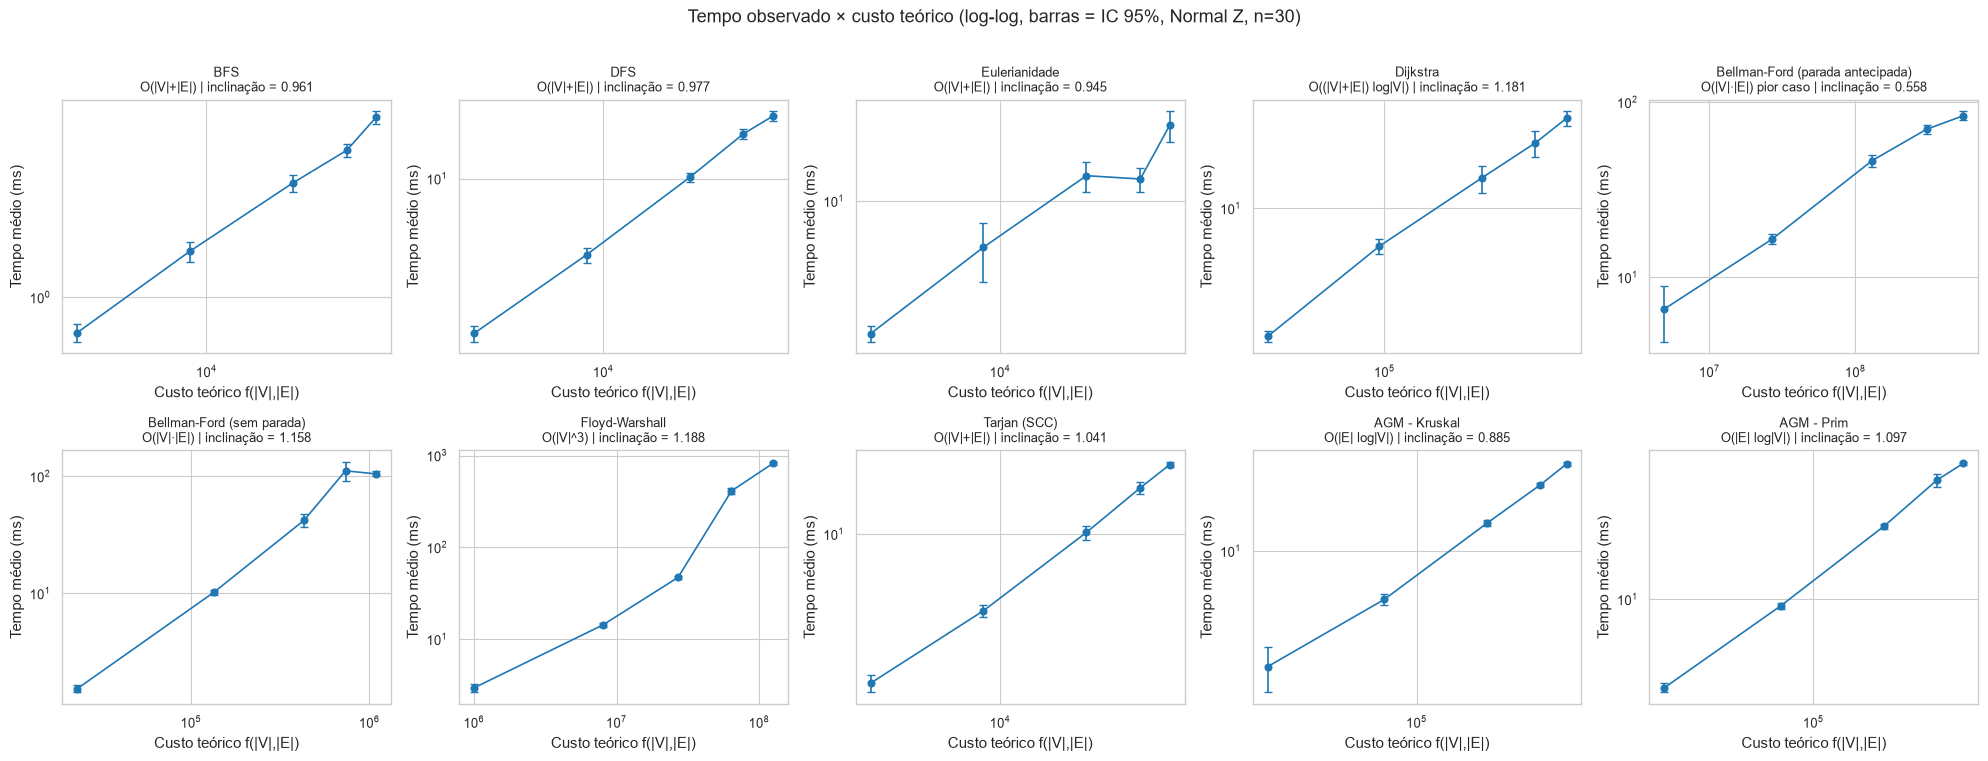

In [ ]:
# --- Tabela principal ---
# Filtra o tamanho de referência de cada algoritmo (grafo inteiro ou V=300) para montar a tabela principal
principal = []
for nome in EXPERIMENTOS:
    sub = df_esc[df_esc["Algoritmo"] == nome]
    alvo = TAM_REF.get(nome, N)
    linha = sub[sub["|V|"] == alvo].iloc[0]
    principal.append({"Algoritmo": nome, "Grafo / escopo": f"|V|={int(linha['|V|'])}, |E|={int(linha['|E|'])}",
                      "Complexidade teórica": linha["Complexidade teórica"],
                      "Média (ms)": round(linha["media_ms"], 4), "Desvio-padrão (ms)": round(linha["dp_ms"], 4),
                      "IC 95% (ms)": linha["IC 95% (ms)"], "n": int(linha["n"])})
df_principal = pd.DataFrame(principal)
display(df_principal)
df_principal.to_csv(TABLES_DIR / "tabela_parte2_principal.csv", index=False)

# --- Inclinações log-log ---
# Ajusta uma reta em log-log (tempo x custo teórico), inclinação próxima de 1 confirma o crescimento previsto
res_incl = []
for nome in EXPERIMENTOS:
    sub = df_esc[df_esc["Algoritmo"] == nome]
    reg = stats.linregress(np.log10(sub["Custo teórico f(V,E)"]), np.log10(sub["media_ms"]))
    res_incl.append({"Algoritmo": nome, "Complexidade teórica": sub["Complexidade teórica"].iloc[0],
                     "Inclinação log-log": round(reg.slope, 3), "R²": round(reg.rvalue ** 2, 4),
                     "Tamanhos |V|": f"{int(sub['|V|'].min())}–{int(sub['|V|'].max())}"})
df_incl = pd.DataFrame(res_incl)
display(df_incl)
df_incl.to_csv(TABLES_DIR / "tabela_parte2_inclinacoes.csv", index=False)

# --- Figura: tempo observado x modelo de custo teórico (um painel por algoritmo) ---
# Plota os 10 gráficos de escalonamento em escala log-log com as barras do IC de 95%
nomes = list(EXPERIMENTOS)
fig, axes = plt.subplots(2, 5, figsize=(20, 7.5))
for ax, nome in zip(axes.ravel(), nomes):
    sub = df_esc[df_esc["Algoritmo"] == nome]
    x, y = sub["Custo teórico f(V,E)"].values, sub["media_ms"].values
    erro = Z_CRIT * sub["dp_ms"].values / np.sqrt(sub["n"].values) # margem de erro do IC 95%
    ax.errorbar(x, y, yerr=erro, fmt="o-", capsize=3, color="#1f77b4")
    incl = df_incl.loc[df_incl["Algoritmo"] == nome, "Inclinação log-log"].iloc[0]
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_title(f"{nome}\n{sub['Complexidade teórica'].iloc[0]} | inclinação = {incl}", fontsize=9.5)
    ax.set_xlabel("Custo teórico f(|V|,|E|)"); ax.set_ylabel("Tempo médio (ms)")
    ax.tick_params(which="minor", labelbottom=False, labelleft=False)
plt.suptitle("Tempo observado × custo teórico (log-log, barras = IC 95%, Normal Z, n=30)", y=1.01)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "parte2_escalonamento_complexidade.png", dpi=300, bbox_inches="tight")
plt.show()